In [18]:
from pathlib import Path
from datetime import datetime
from uuid import uuid4
import sys
import random

import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets
import timm
from PIL import Image
import matplotlib.pyplot as plt

PROJECT_DIR = Path(r"D:\workspace\preparation\dinov3_11")
DATA_DIR = PROJECT_DIR / "fsdataset"

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Python：", sys.executable)
print("PyTorch：", torch.__version__)
print("timm：", timm.__version__)
print("计算设备：", device)

if device.type == "cuda":
    print("GPU：", torch.cuda.get_device_name(0))

assert DATA_DIR.is_dir(), f"没有找到数据集，请检查：{DATA_DIR}"

Python： F:\Program\Miniforge3\envs\dinov3_11\python.exe
PyTorch： 2.4.1+cu124
timm： 1.0.24
计算设备： cuda
GPU： NVIDIA GeForce RTX 4060 Laptop GPU


In [19]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

In [20]:
MODEL_NAME = "vit_small_patch16_dinov3.lvd1689m"

backbone = timm.create_model(
    MODEL_NAME,
    pretrained=True,
    num_classes=0,
)

backbone = backbone.to(device)

In [21]:
backbone.requires_grad_(False)
backbone.eval()

trainable_count = sum(
    p.numel() for p in backbone.parameters() if p.requires_grad
)
print("骨干可训练参数数量：", trainable_count)

骨干可训练参数数量： 0


In [22]:
feature_dim = backbone.num_features
data_config = timm.data.resolve_model_data_config(backbone)

print("特征维度：", feature_dim)
print("输入尺寸：", data_config["input_size"])
print("均值：", data_config["mean"])
print("标准差：", data_config["std"])

特征维度： 384
输入尺寸： (3, 256, 256)
均值： (0.485, 0.456, 0.406)
标准差： (0.229, 0.224, 0.225)


In [23]:
from torchvision import transforms


def make_rf_transform(config):
    height, width = config["input_size"][-2:]

    return transforms.Compose([
        transforms.Resize((height, width)),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=config["mean"],
            std=config["std"],
        ),
    ])


train_transform = make_rf_transform(data_config)
eval_transform = make_rf_transform(data_config)

In [24]:
train_dataset = datasets.ImageFolder(
    DATA_DIR / "train", transform=train_transform
)

val_dataset = datasets.ImageFolder(
    DATA_DIR / "val", transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    DATA_DIR / "test", transform=eval_transform

)

In [25]:
class_names = train_dataset.classes
num_classes = len(class_names)

print("类别名称：", class_names)
print("类别编号：", train_dataset.class_to_idx)

for name, dataset in (
    ("train", train_dataset),
    ("val", val_dataset),
    ("test", test_dataset),
):
    print(name, "图片数量：", len(dataset))

assert (
    train_dataset.class_to_idx
    == val_dataset.class_to_idx
    == test_dataset.class_to_idx
)

类别名称： ['2FSK', 'CW', 'LFM']
类别编号： {'2FSK': 0, 'CW': 1, 'LFM': 2}
train 图片数量： 12
val 图片数量： 3
test 图片数量： 3


In [26]:
BATCH_SIZE = 2

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=0, generator=torch.Generator().manual_seed(SEED)
)

val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)

test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)

In [27]:
probe_images, probe_labels = next(iter(val_loader))
probe_images = probe_images.to(device)

print("图片形状：", probe_images.shape)
print("标签形状：", probe_labels.shape)
print("标签内容：", probe_labels.tolist())
print("标签类型：", probe_labels.dtype)

图片形状： torch.Size([2, 3, 256, 256])
标签形状： torch.Size([2])
标签内容： [0, 1]
标签类型： torch.int64


In [28]:
with torch.no_grad():
    features_before = backbone(probe_images).clone()

print("特征形状：", features_before.shape)
print("第一张图片的前 8 个特征数值：")
print(features_before[0, :8].cpu())

特征形状： torch.Size([2, 384])
第一张图片的前 8 个特征数值：
tensor([ 0.0213,  0.3395,  0.2421,  0.0721,  0.2138, -0.2782,  0.3420,  0.4795])


F:\Program\Miniforge3\envs\dinov3_11\Lib\site-packages\timm\models\eva.py:240: UserWarning: 1Torch was not compiled with flash attention. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\aten\src\ATen\native\transformers\cuda\sdp_utils.cpp:555.)
  x = F.scaled_dot_product_attention(


In [29]:
feature_dim ,num_classes

(384, 3)

In [30]:
def make_head(feature_dim, num_classes):
    return nn.Sequential(
        nn.Linear(feature_dim, 256),
        nn.ReLU(),
        nn.Dropout(0.1),
        nn.Linear(256, num_classes),
    )

In [31]:
head = make_head(feature_dim, num_classes).to(device)
head.eval()

with torch.no_grad():
    logits = head(features_before)

print("类别分数形状：", logits.shape)
print(logits.cpu())

类别分数形状： torch.Size([2, 3])
tensor([[ 0.1219, -0.0542, -0.0455],
        [ 0.1099,  0.0040, -0.0367]])


In [32]:
probabilities = logits.softmax(dim=1)

print("三个类别的归一化数值：")
print(probabilities.cpu())

print("每张图片的数值之和：")
print(probabilities.sum(dim=1).cpu())

三个类别的归一化数值：
tensor([[0.3725, 0.3124, 0.3151],
        [0.3619, 0.3255, 0.3126]])
每张图片的数值之和：
tensor([1.0000, 1.0000])


In [33]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    head.parameters(),
    lr=0.001,
)

In [34]:
images, labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

backbone.eval()
head.train()

weight_before = head[0].weight.detach().clone()
optimizer.zero_grad(set_to_none=True)

In [35]:
with torch.no_grad():
    features = backbone(images)

print("特征形状：", features.shape)
print("特征是否需要梯度：", features.requires_grad)

特征形状： torch.Size([2, 384])
特征是否需要梯度： False


In [36]:
logits = head(features)

print("分数形状：", logits.shape)
print("分数是否需要梯度：", logits.requires_grad)


分数形状： torch.Size([2, 3])
分数是否需要梯度： True


In [37]:
loss = criterion(logits, labels)

print("正确类别编号：", labels.tolist())
print("当前损失：", loss.item())

正确类别编号： [1, 0]
当前损失： 1.054325819015503


In [38]:
loss.backward()

print("分类头第一层是否得到梯度：", head[0].weight.grad is not None)
print(
    "骨干参数是否都没有梯度：",
    all(p.grad is None for p in backbone.parameters()),
)

分类头第一层是否得到梯度： True
骨干参数是否都没有梯度： True


In [39]:
optimizer.step()

weight_change = (head[0].weight - weight_before).abs().max().item()
print("第一层权重的最大变化：", weight_change)

第一层权重的最大变化： 0.0010000001639127731


# 正式实验

In [40]:
torch.manual_seed(SEED)

head = make_head(feature_dim, num_classes).to(device)

optimizer = torch.optim.Adam(
    head.parameters(),
    lr=0.001,
)


In [41]:
@torch.no_grad()
def evaluate(data_loader, classifier):
    backbone.eval()
    classifier.eval()

    loss_sum = 0.0
    correct = 0
    total = 0

    for images, labels in data_loader:
        images = images.to(device)
        labels = labels.to(device)

        features = backbone(images)
        logits = classifier(features)
        loss = criterion(logits, labels)

        batch_size = labels.size(0)
        loss_sum += loss.item() * batch_size
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += batch_size

    return loss_sum / total, 100 * correct / total

In [42]:
baseline_loss, baseline_acc = evaluate(val_loader, head)

print(f"训练前验证损失：{baseline_loss:.4f}")
print(f"训练前验证准确率：{baseline_acc:.2f}%")

训练前验证损失：1.1031
训练前验证准确率：33.33%


In [43]:
def train_one_batch(images, labels):
    images = images.to(device)
    labels = labels.to(device)

    optimizer.zero_grad(set_to_none=True)

    with torch.no_grad():
        features = backbone(images)

    logits = head(features)
    loss = criterion(logits, labels)

    loss.backward()
    optimizer.step()

    correct = (logits.argmax(dim=1) == labels).sum().item()
    return loss.item(), correct, labels.size(0)

In [44]:
def train_one_epoch():
    backbone.eval()
    head.train()

    loss_sum = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        batch_loss, batch_correct, batch_size = train_one_batch(images, labels)

        loss_sum += batch_loss * batch_size
        correct += batch_correct
        total += batch_size

    return loss_sum / total, 100 * correct / total

In [45]:
EPOCHS = 10
history = []

best_val_acc = -1.0
best_epoch = 0
best_state = None

In [46]:
for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = train_one_epoch()
    val_loss, val_acc = evaluate(val_loader, head)

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc,
    })

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch = epoch
        best_state = {
            name: tensor.detach().cpu().clone()
            for name, tensor in head.state_dict().items()
        }

    print(
        f"第 {epoch:02d} 轮 | "
        f"训练损失 {train_loss:.4f} | "
        f"训练准确率 {train_acc:.2f}% | "
        f"验证准确率 {val_acc:.2f}%"
    )

第 01 轮 | 训练损失 1.2956 | 训练准确率 33.33% | 验证准确率 33.33%
第 02 轮 | 训练损失 0.9155 | 训练准确率 58.33% | 验证准确率 100.00%
第 03 轮 | 训练损失 0.7884 | 训练准确率 100.00% | 验证准确率 100.00%
第 04 轮 | 训练损失 0.6750 | 训练准确率 100.00% | 验证准确率 100.00%
第 05 轮 | 训练损失 0.5010 | 训练准确率 100.00% | 验证准确率 100.00%
第 06 轮 | 训练损失 0.3813 | 训练准确率 100.00% | 验证准确率 100.00%
第 07 轮 | 训练损失 0.2830 | 训练准确率 100.00% | 验证准确率 100.00%
第 08 轮 | 训练损失 0.2040 | 训练准确率 100.00% | 验证准确率 100.00%
第 09 轮 | 训练损失 0.1461 | 训练准确率 100.00% | 验证准确率 100.00%
第 10 轮 | 训练损失 0.1014 | 训练准确率 100.00% | 验证准确率 100.00%


In [47]:
head.load_state_dict(best_state)
head.eval()

print("选用轮次：", best_epoch)
print(f"最佳验证准确率：{best_val_acc:.2f}%")
print(f"训练前验证准确率：{baseline_acc:.2f}%")

选用轮次： 2
最佳验证准确率：100.00%
训练前验证准确率：33.33%


In [48]:
with torch.no_grad():
    features_after = backbone(probe_images)

same_features = torch.allclose(
    features_before, features_after,
    atol=1e-5, rtol=1e-4,
)

print("同一批图片的骨干特征是否保持一致：", same_features)

同一批图片的骨干特征是否保持一致： True


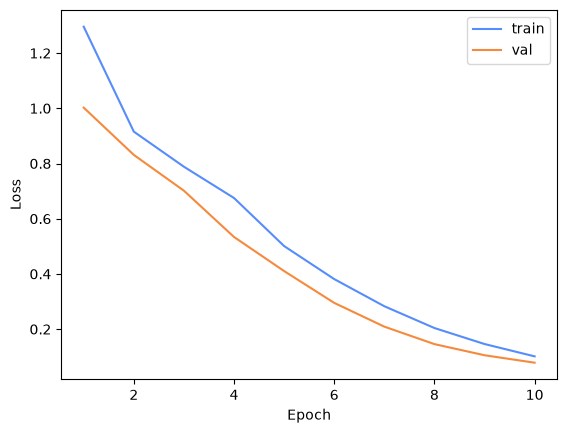

In [49]:
epochs = [row["epoch"] for row in history]

plt.plot(epochs, [r["train_loss"] for r in history], label="train")
plt.plot(epochs, [r["val_loss"] for r in history], label="val")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [50]:
run_name = datetime.now().strftime("%Y%m%d_%H%M%S") + "_" + uuid4().hex[:6]

RUN_DIR = PROJECT_DIR / "runs" / run_name
RUN_DIR.mkdir(parents=True, exist_ok=False)

CKPT_PATH = RUN_DIR / "best_head.pth"
print("权重保存位置：", CKPT_PATH)

权重保存位置： D:\workspace\preparation\dinov3_11\runs\20261010_084926_ccc0f3\best_head.pth


In [51]:
torch.save({
    "classifier_state_dict": best_state,
    "feature_dim": feature_dim,
    "num_classes": num_classes,
    "class_to_idx": train_dataset.class_to_idx,
    "model_name": MODEL_NAME,
    "data_config": data_config,
    "best_epoch": best_epoch,
    "best_val_acc": best_val_acc,
}, CKPT_PATH)

print("保存完成")

保存完成


In [52]:
checkpoint = torch.load(
    CKPT_PATH,
    map_location="cpu",
    weights_only=True,
)

print("保存的内容：", list(checkpoint.keys()))
print("骨干型号：", checkpoint["model_name"])
print("类别映射：", checkpoint["class_to_idx"])

保存的内容： ['classifier_state_dict', 'feature_dim', 'num_classes', 'class_to_idx', 'model_name', 'data_config', 'best_epoch', 'best_val_acc']
骨干型号： vit_small_patch16_dinov3.lvd1689m
类别映射： {'2FSK': 0, 'CW': 1, 'LFM': 2}


# 验证复现

In [53]:
inference_backbone = timm.create_model(
    checkpoint["model_name"],
    pretrained=True,
    num_classes=0,
).to(device)

inference_backbone.requires_grad_(False)

Eva(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 384, kernel_size=(16, 16), stride=(16, 16))
    (norm): Identity()
  )
  (pos_drop): Dropout(p=0.0, inplace=False)
  (rope): RotaryEmbeddingDinoV3()
  (norm_pre): Identity()
  (blocks): ModuleList(
    (0-11): 12 x EvaBlock(
      (norm1): LayerNorm((384,), eps=1e-05, elementwise_affine=True)
      (attn): EvaAttention(
        (qkv): Linear(in_features=384, out_features=1152, bias=False)
        (q_norm): Identity()
        (k_norm): Identity()
        (attn_drop): Dropout(p=0.0, inplace=False)
        (norm): Identity()
        (proj): Linear(in_features=384, out_features=384, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path1): Identity()
      (norm2): LayerNorm((384,), eps=1e-05, elementwise_affine=True)
      (mlp): Mlp(
        (fc1): Linear(in_features=384, out_features=1536, bias=True)
        (act): GELU(approximate='none')
        (drop1): Dropout(p=0.0, inplace=False)
        (norm)

In [54]:
inference_head = make_head(
    checkpoint["feature_dim"],
    checkpoint["num_classes"],
).to(device)

inference_head.load_state_dict(checkpoint["classifier_state_dict"])

inference_model = nn.Sequential(inference_backbone, inference_head)
inference_model.eval()

Sequential(
  (0): Eva(
    (patch_embed): PatchEmbed(
      (proj): Conv2d(3, 384, kernel_size=(16, 16), stride=(16, 16))
      (norm): Identity()
    )
    (pos_drop): Dropout(p=0.0, inplace=False)
    (rope): RotaryEmbeddingDinoV3()
    (norm_pre): Identity()
    (blocks): ModuleList(
      (0-11): 12 x EvaBlock(
        (norm1): LayerNorm((384,), eps=1e-05, elementwise_affine=True)
        (attn): EvaAttention(
          (qkv): Linear(in_features=384, out_features=1152, bias=False)
          (q_norm): Identity()
          (k_norm): Identity()
          (attn_drop): Dropout(p=0.0, inplace=False)
          (norm): Identity()
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (drop_path1): Identity()
        (norm2): LayerNorm((384,), eps=1e-05, elementwise_affine=True)
        (mlp): Mlp(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='n

In [55]:
inference_transform = make_rf_transform(checkpoint["data_config"])

idx_to_class = {
    index: name
    for name, index in checkpoint["class_to_idx"].items()
}

print(idx_to_class)

{0: '2FSK', 1: 'CW', 2: 'LFM'}


In [56]:
with torch.no_grad():
    original_logits = head(backbone(probe_images))
    reloaded_logits = inference_model(probe_images)

same_outputs = torch.allclose(
    original_logits, reloaded_logits,
    atol=1e-5, rtol=1e-4,
)

print("保存前后输出是否一致：", same_outputs)
assert same_outputs, "请检查模型结构、权重和骨干型号"

保存前后输出是否一致： True


In [57]:
assert test_dataset.class_to_idx == checkpoint["class_to_idx"]
test_dataset.transform = inference_transform

true_labels = []
predicted_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        logits = inference_model(images.to(device))
        predictions = logits.argmax(dim=1)

        true_labels.extend(labels.tolist())
        predicted_labels.extend(predictions.cpu().tolist())

In [58]:
correct = sum(
    actual == predicted
    for actual, predicted in zip(true_labels, predicted_labels)
)

print(f"测试准确率：{100 * correct / len(true_labels):.2f}%")
print(f"预测正确：{correct}/{len(true_labels)}")

for (path, actual), predicted in zip(test_dataset.samples, predicted_labels):
    print(
        Path(path).name,
        "真实：", idx_to_class[actual],
        "预测：", idx_to_class[predicted],
    )

测试准确率：100.00%
预测正确：3/3
2FSK_0001_event06_window01.png 真实： 2FSK 预测： 2FSK
CW_0001_event03_window01.png 真实： CW 预测： CW
LFM_0001_event04_window01.png 真实： LFM 预测： LFM


In [59]:
IMAGE_PATH = Path(test_dataset.samples[0][0])

with Image.open(IMAGE_PATH) as source_image:
    image = source_image.convert("RGB")

print("推理图片：", IMAGE_PATH)
print("原始图片尺寸：", image.size)

推理图片： D:\workspace\preparation\dinov3_11\fsdataset\test\2FSK\2FSK_0001_event06_window01.png
原始图片尺寸： (256, 256)


In [60]:
image_tensor = inference_transform(image)
print("单张图片：", image_tensor.shape)

input_batch = image_tensor.unsqueeze(0).to(device)
print("模型输入：", input_batch.shape)

单张图片： torch.Size([3, 256, 256])
模型输入： torch.Size([1, 3, 256, 256])


In [61]:
with torch.no_grad():
    output_logits = inference_model(input_batch)

print(output_logits.cpu())

tensor([[ 0.3239, -0.2079, -0.0797]])


预测类别： 2FSK
2FSK：44.34%
CW：26.05%
LFM：29.61%


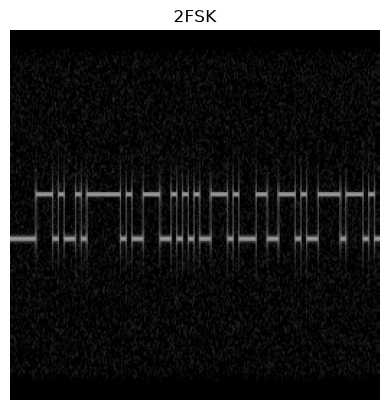

In [62]:
scores = output_logits.softmax(dim=1)[0].cpu()
predicted_index = scores.argmax().item()

print("预测类别：", idx_to_class[predicted_index])

for index, score in enumerate(scores.tolist()):
    print(f"{idx_to_class[index]}：{score:.2%}")

plt.imshow(image)
plt.title(idx_to_class[predicted_index])
plt.axis("off")
plt.show()